# 03 Simulation: the IP against two alternative designs

**Question.** Over the whole session, how close does each method come to the ideal forest, how much
does it disrupt what the student has seen, and when does the IP decide differently from simply
taking the judge's top option?

Methods: `chronological` (no judge, one tree per 5 consecutive prompts, the chat-sidebar status
quo), `judge_argmax` (the judge's highest-fit option, restructure proposals ignored, no IP) and
`ip`. The judge-based methods run with the `OracleJudge` (noise 0 and 0.2) and, once a model is
chosen, with the `LLMJudge`. Every forest is validated after every step.

Metrics: pairwise F1 of "same topic" and "same tree" against the ideal forest (label-independent),
disruption (moved prompts weighted by `w`, moved topics, deleted categories), balance (topics above
`U`, below `L`), the action against the intended one, and whether the IP differs from `judge_argmax`
given the same judge output.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import viz
from forest.ip import ACTIONS, Params, load_config
from forest.model import load_ideal

cfg = load_config(ROOT / "config.yaml")
P = Params.from_config(cfg)
ideal = load_ideal()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

import numpy as np

from forest.ip import solve
from forest.judge import LLMJudge, OracleJudge
from forest.metrics import pair_f1
from forest.simulate import run, summary

## Runs

In [2]:
runs = [run("chronological", ideal, P=P)]
for noise in (cfg["oracle"]["noise"], 0.2):
    j = OracleJudge(ideal, noise, cfg["seed"])
    runs += [run("judge_argmax", ideal, j, P), run("ip", ideal, j, P)]
llm = LLMJudge(cfg)
if llm.available:
    runs += [run("judge_argmax", ideal, llm, P), run("ip", ideal, llm, P)]
else:
    print("LLM runs skipped: no model chosen yet (config.yaml llm.model)")
by_name = {r.name: r for r in runs}
table = summary(runs)
table.round(3)

LLM runs skipped: no model chosen yet (config.yaml llm.model)


,run,method,judge,final f1 topic,final f1 tree,moved prompts (w),moved topics,deleted,restructures,over U (final),under L (final),differs from argmax,max vars,max constrs,actions
0,chronological,chronological,none,0.175,0.288,0.000,0,0,0,0,0,NaN,NaN,NaN,a:20 c:4 d:1
1,judge_argmax_oracle(noise=0.0),judge_argmax,oracle(noise=0.0),1.000,1.000,0.000,0,0,0,1,0,NaN,NaN,NaN,a:17 b:5 c:1 d:2
2,ip_oracle(noise=0.0),ip,oracle(noise=0.0),0.793,0.957,2.933,0,0,1,0,1,0.32,129.0,205.0,a:16 b:4 c:3 d:1 e:1
3,judge_argmax_oracle(noise=0.2),judge_argmax,oracle(noise=0.2),0.933,1.000,0.000,0,0,0,1,1,NaN,NaN,NaN,a:16 b:6 c:1 d:2
4,ip_oracle(noise=0.2),ip,oracle(noise=0.2),0.793,1.000,1.602,0,0,1,0,1,0.08,137.0,216.0,a:16 b:6 c:1 d:1 e:1


The IP's run with the noisy oracle, step by step: the action next to the intended one.

In [3]:
main_ip = by_name.get(f"ip_llm({cfg['llm']['model']})", by_name["ip_oracle(noise=0.2)"])
main_argmax = by_name.get(f"judge_argmax_llm({cfg['llm']['model']})", by_name["judge_argmax_oracle(noise=0.2)"])
cols = ["step", "prompt", "intended", "action", "f1_topic", "f1_tree", "moved_prompts", "moved_topics", "deleted",
        "over_U", "under_L", "differs_from_argmax", "vars", "constrs", "solve_s"]
print(main_ip.name)
main_ip.table()[cols].round(3)

ip_oracle(noise=0.2)


,step,prompt,intended,action,f1_topic,f1_tree,moved_prompts,moved_topics,deleted,over_U,under_L,differs_from_argmax,vars,constrs,solve_s
0,1,p01,d,d,1.000,1.000,0,0,0,0,1,False,9,12,0.0
1,2,p03,b,a,0.000,1.000,0,0,0,0,0,True,20,29,0.0
2,3,p04,a,b,0.000,1.000,0,0,0,0,1,False,23,34,0.0
3,4,p02,a,a,0.400,1.000,0,0,0,0,1,False,26,40,0.0
4,5,p05,a,a,0.500,1.000,0,0,0,0,0,False,28,44,0.0
5,6,p10,b,b,0.500,1.000,0,0,0,0,1,False,45,68,0.0
6,7,p15,c,b,0.500,1.000,0,0,0,0,3,False,55,81,0.0
7,8,p13,b,b,0.500,1.000,0,0,0,0,3,False,65,97,0.0
8,9,p06,a,a,0.615,1.000,0,0,0,0,3,False,68,103,0.0
9,10,p11,a,a,0.667,1.000,0,0,0,0,3,False,78,117,0.0


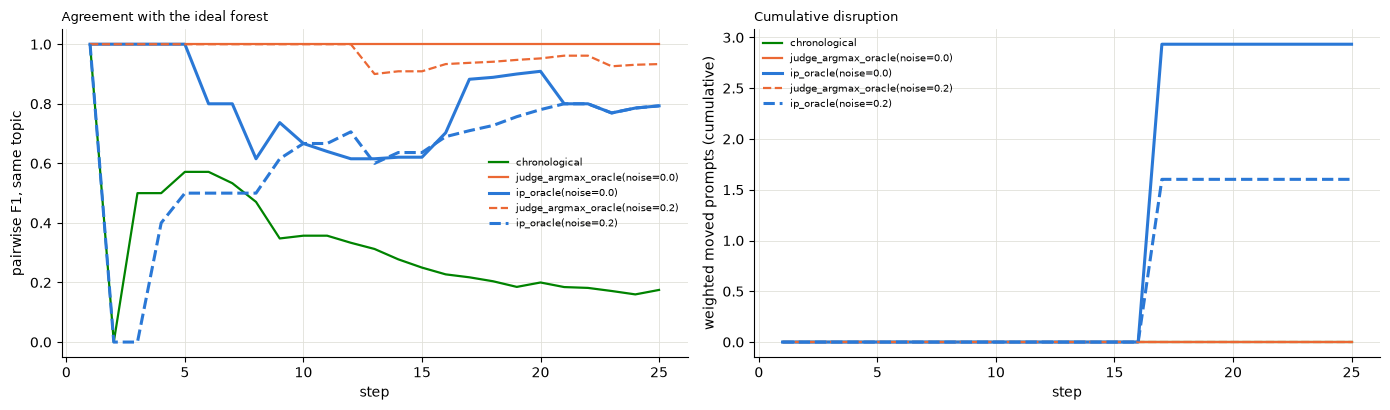

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
viz.line_runs(runs, "f1_topic", axes[0], "pairwise F1, same topic")
axes[0].set_title("Agreement with the ideal forest", fontsize=9, loc="left")
viz.line_runs(runs, "moved_prompts_w", axes[1], "weighted moved prompts (cumulative)", cumulative=True)
axes[1].set_title("Cumulative disruption", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig(FIG / "03_f1_and_disruption.png", dpi=150, bbox_inches="tight")
plt.show()

## Browsing the runs
A slider over the steps of the main `ip` and `judge_argmax` runs (needs a live kernel), and a
storyboard of every step saved to `outputs/figures/<run>/step_XX.png`.

In [5]:
viz.step_browser(main_ip, P)

interactive(children=(IntSlider(value=1, description='step', max=25, min=1), Output()), _dom_classes=('widget-…

<function forest.viz.step_browser.<locals>.show(step: 'int')>

In [6]:
viz.step_browser(main_argmax, P)

interactive(children=(IntSlider(value=1, description='step', max=25, min=1), Output()), _dom_classes=('widget-…

<function forest.viz.step_browser.<locals>.show(step: 'int')>

In [7]:
for r in (main_ip, main_argmax):
    print("saved", viz.save_storyboard(r, P=P).relative_to(ROOT))

saved outputs/figures/ip_oracle_noise_0.2


saved outputs/figures/judge_argmax_oracle_noise_0.2


## Ideal, IP and argmax side by side
At the final step and at two steps where `ip` and `judge_argmax` decide differently. Prompts that
are not in their ideal topic are red.

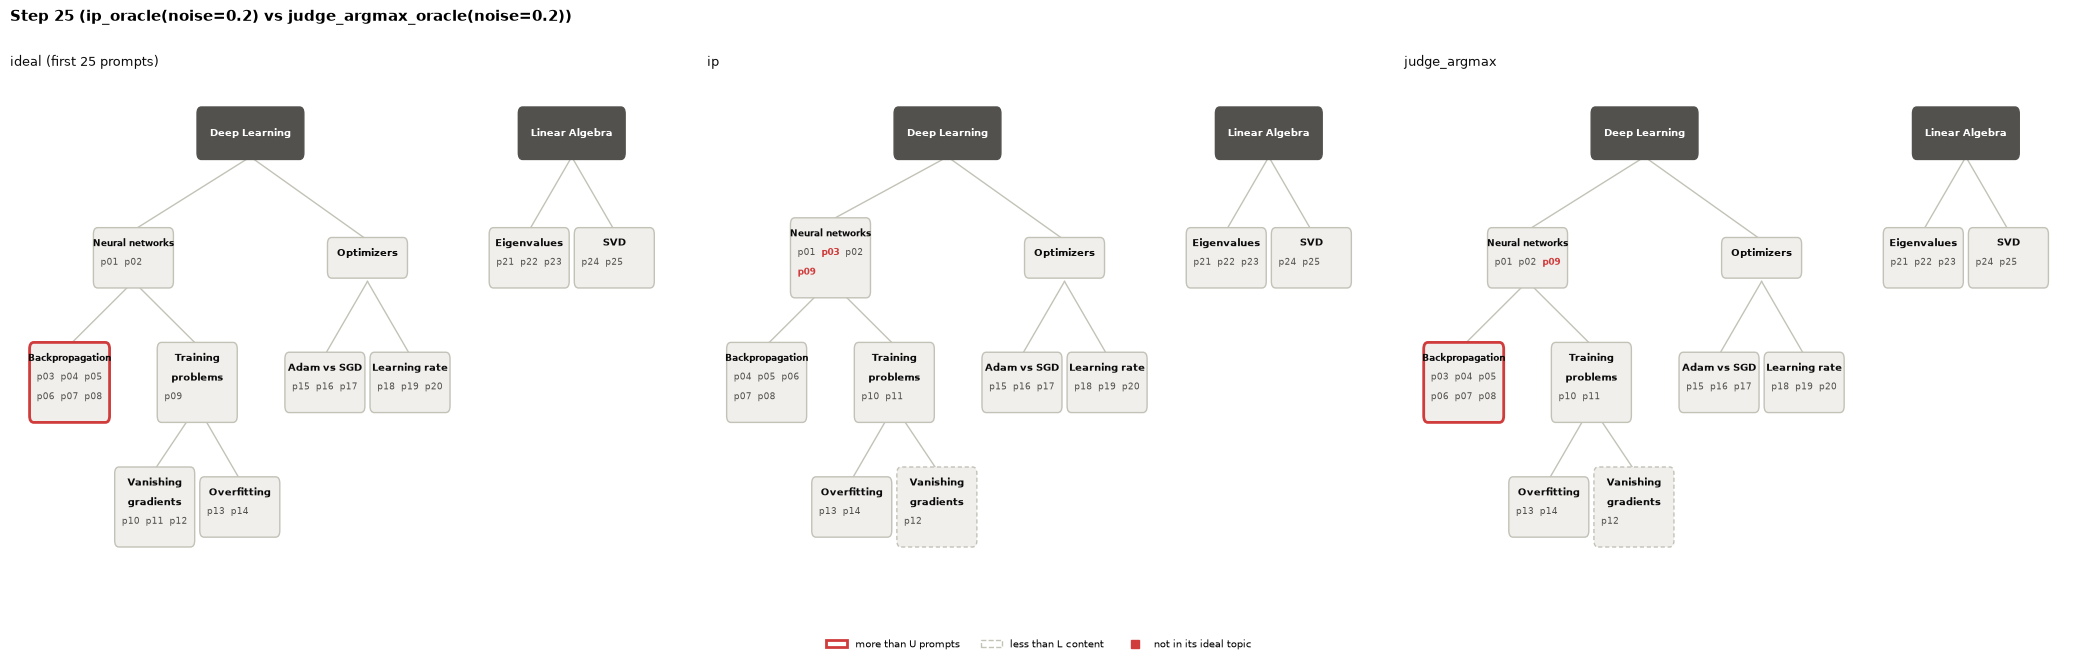

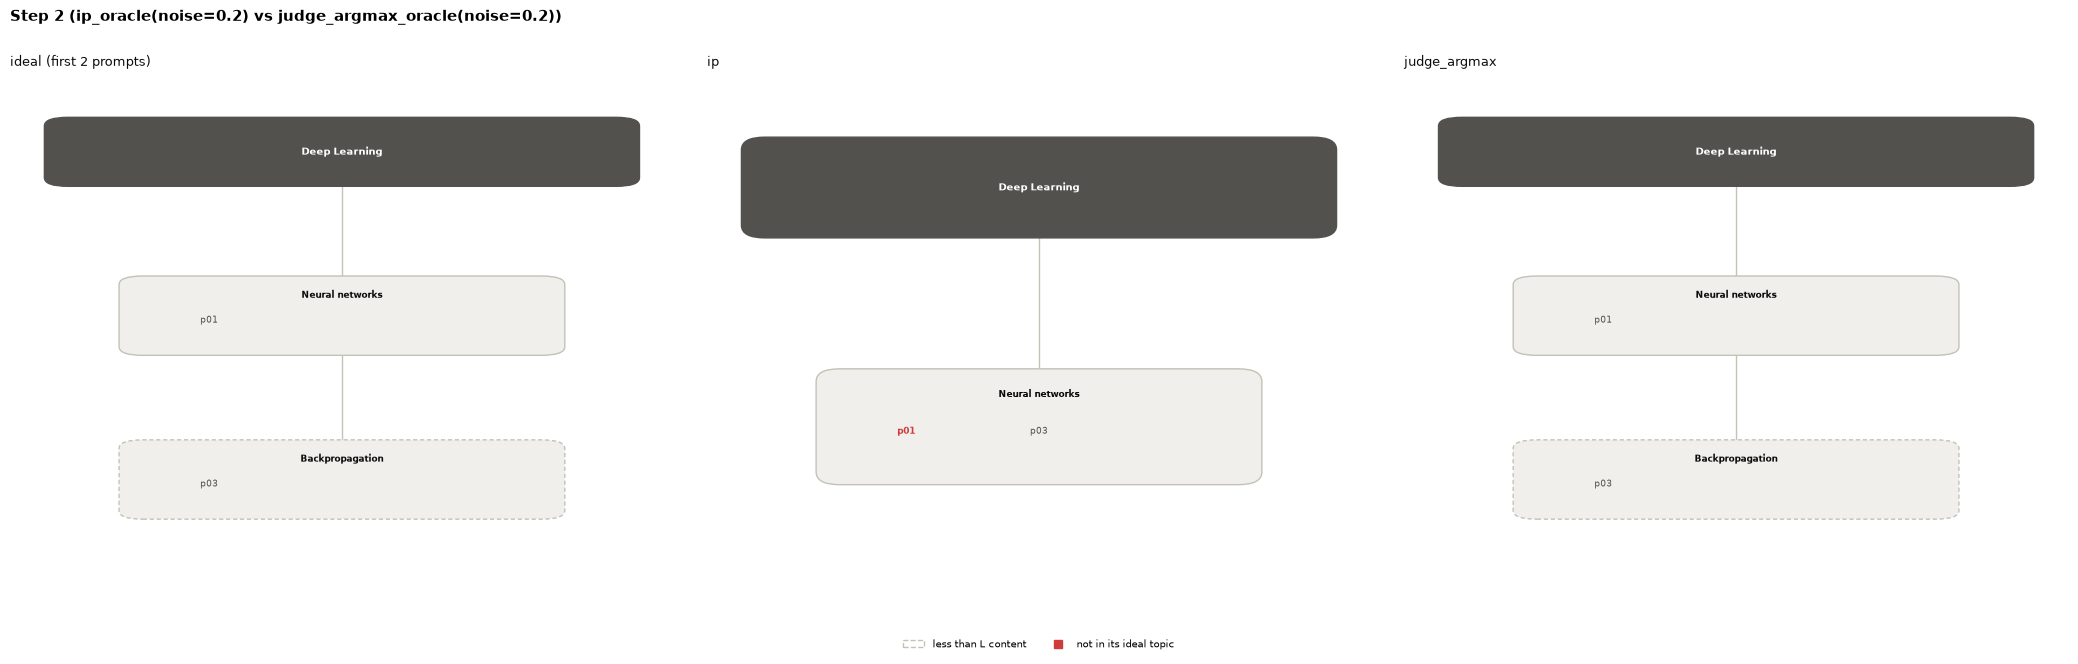

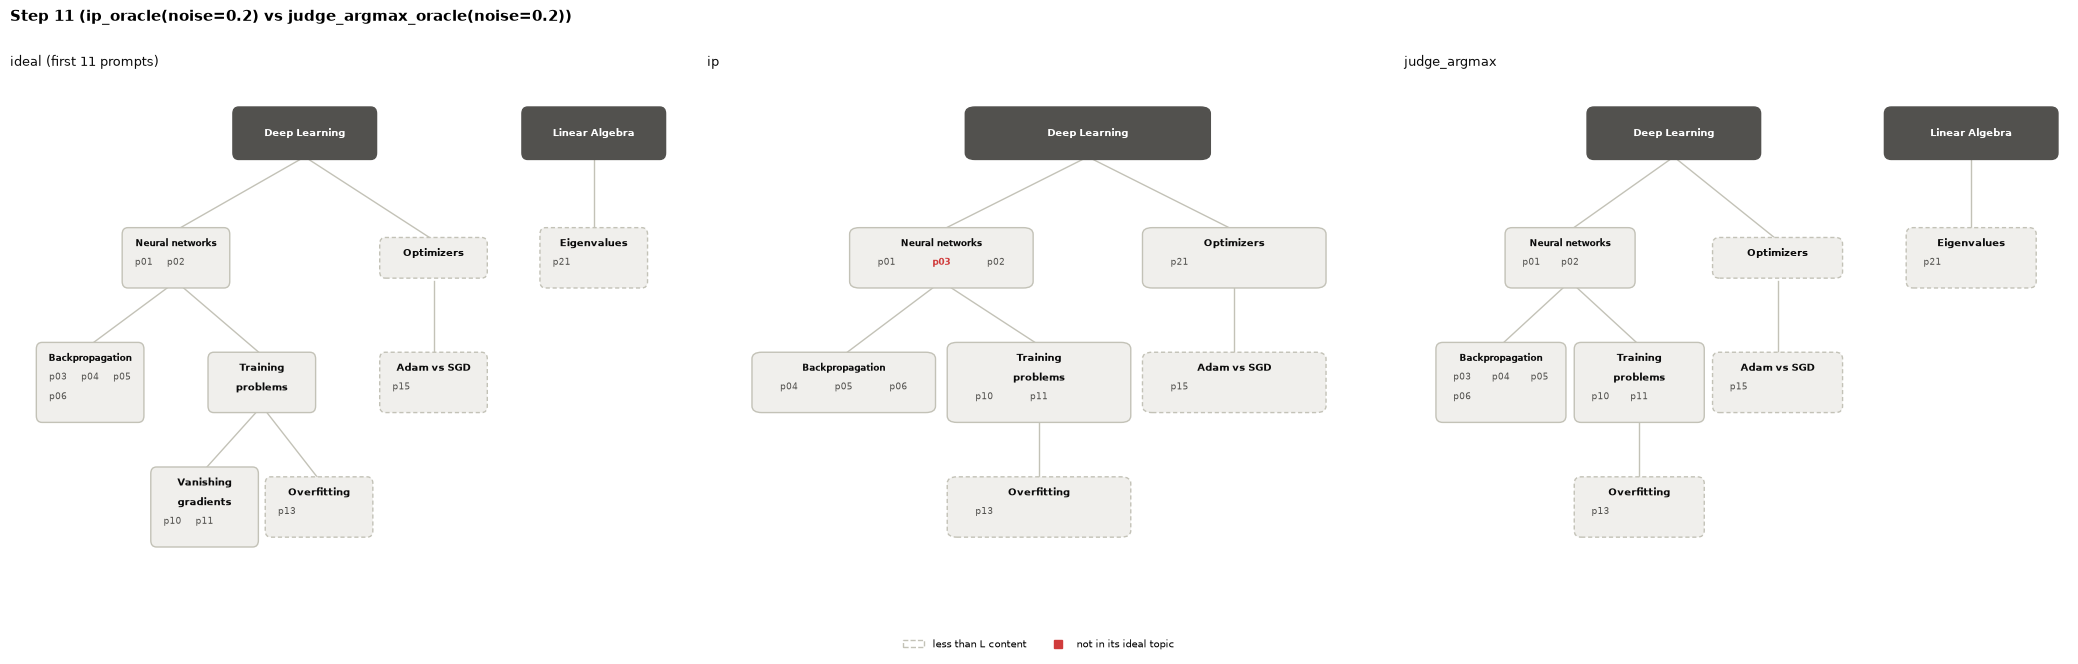

In [8]:
diff_steps = [s.step for s in main_ip.steps if s.differs][:2]
for k in [len(ideal.arrival)] + diff_steps:
    fig = viz.compare_view({f"ideal (first {k} prompts)": ideal.upto(k), "ip": main_ip.steps[k - 1].after,
                            "judge_argmax": main_argmax.steps[k - 1].after}, ideal, P,
                           title=f"Step {k} ({main_ip.name} vs {main_argmax.name})")
    fig.savefig(FIG / f"03_compare_step{k:02d}.png", dpi=130, bbox_inches="tight")
    plt.show()

## What-if 1: the stability weights over the whole session
The IP with the oracle judge (noise 0), re-run for every pair of `mu` (cost per weighted moved
prompt) and `F` (fixed cost of a restructure), log-spaced from 0.05 to 2. Each setting gives a
different trajectory, which is why this uses the oracle: no LLM calls.

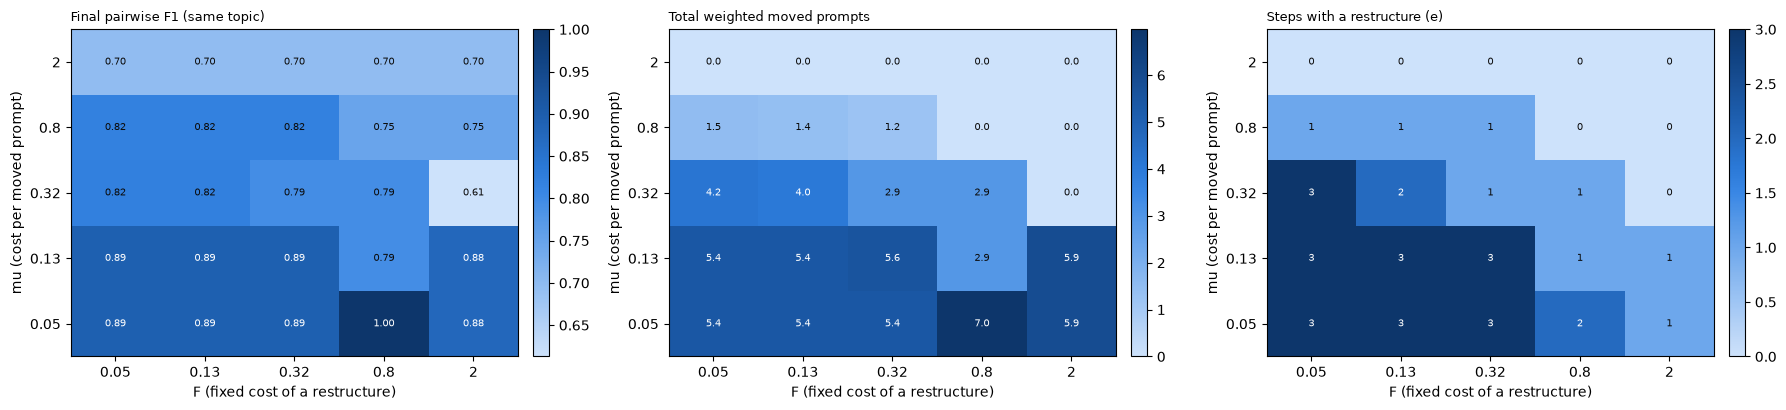

final F1


F,0.050,0.126,0.316,0.795,2.000
mu,,,,,
0.050,0.893,0.893,0.893,1.000,0.877
0.126,0.893,0.893,0.893,0.793,0.877
0.316,0.821,0.821,0.793,0.793,0.613
0.795,0.818,0.818,0.818,0.746,0.746
2.000,0.696,0.696,0.696,0.696,0.696


disruption


F,0.050,0.126,0.316,0.795,2.000
mu,,,,,
0.050,5.400,5.400,5.400,6.976,5.9
0.126,5.400,5.400,5.553,2.933,5.9
0.316,4.162,4.000,2.933,2.933,0.0
0.795,1.493,1.404,1.222,0.000,0.0
2.000,0.000,0.000,0.000,0.000,0.0


restructures


F,0.050,0.126,0.316,0.795,2.000
mu,,,,,
0.050,3,3,3,2,1
0.126,3,3,3,1,1
0.316,3,2,1,1,0
0.795,1,1,1,0,0
2.000,0,0,0,0,0


In [9]:
GRID = [float(f"{v:.3g}") for v in np.geomspace(0.05, 2, 5)]
oracle0 = OracleJudge(ideal, cfg["oracle"]["noise"], cfg["seed"])
rows = []
for mu in GRID:
    for F_ in GRID:
        t = run("ip", ideal, oracle0, P.replace(mu=mu, F=F_), save=False).table()
        rows.append({"mu": mu, "F": F_, "final F1": t["f1_topic"].iloc[-1], "disruption": t["moved_prompts_w"].sum(),
                     "restructures": int((t["action"] == "e").sum())})
sweep = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
viz.heatmap(sweep.pivot(index="mu", columns="F", values="final F1"), axes[0], "Final pairwise F1 (same topic)")
viz.heatmap(sweep.pivot(index="mu", columns="F", values="disruption"), axes[1], "Total weighted moved prompts", "{:.1f}")
viz.heatmap(sweep.pivot(index="mu", columns="F", values="restructures"), axes[2], "Steps with a restructure (e)", "{:.0f}")
fig.tight_layout()
fig.savefig(FIG / "03_whatif_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()
for col in ("final F1", "disruption", "restructures"):
    print(col)
    display(sweep.pivot(index="mu", columns="F", values=col).round(3))

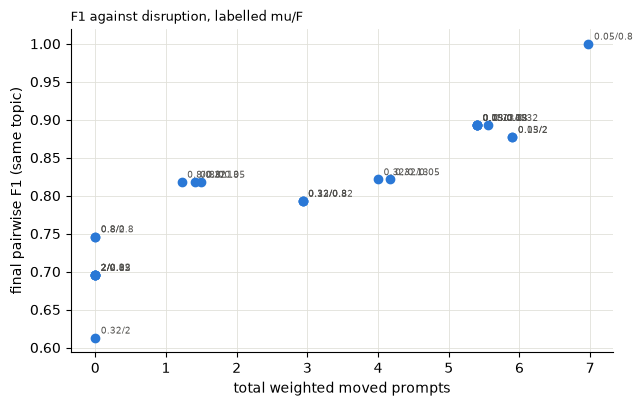

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(sweep["disruption"], sweep["final F1"], color=viz.METHOD_COLOR["ip"], s=36, zorder=3)
for _, r in sweep.iterrows():
    ax.annotate(f"{r['mu']:.2g}/{r['F']:.2g}", (r["disruption"], r["final F1"]), xytext=(4, 3),
                textcoords="offset points", fontsize=6.5, color=viz.INK2)
ax.set_xlabel("total weighted moved prompts")
ax.set_ylabel("final pairwise F1 (same topic)")
ax.set_title("F1 against disruption, labelled mu/F", fontsize=9, loc="left")
ax.grid(color="#e1e0d9", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIG / "03_whatif_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## What-if 2: one step, re-solved across the grid
One fixed step of the main run, re-solved with its stored judge output (so no new LLM calls) for
every `mu` and `F`: which action wins where. The step is the one where the most outcomes compete.

ip_oracle(noise=0.2), step 17: 'What does it mean geometrically that a vector is an eigenvector?' (intended a)


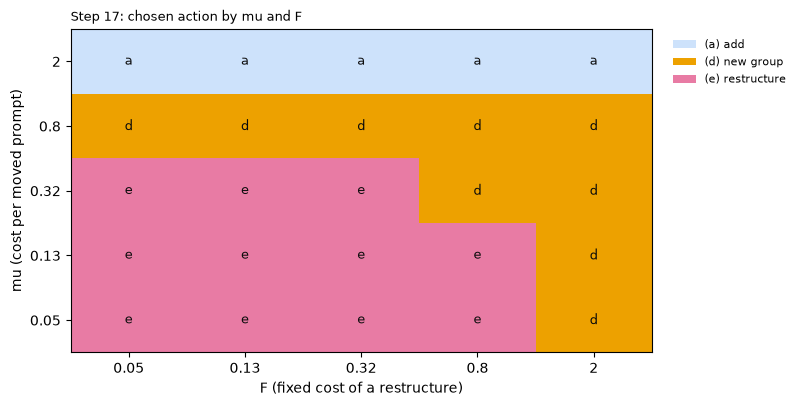

F,0.050,0.126,0.316,0.795,2.000
mu,,,,,
0.050,e,e,e,e,d
0.126,e,e,e,e,d
0.316,e,e,e,d,d
0.795,d,d,d,d,d
2.000,a,a,a,a,a


In [11]:
def actions_over_grid(s):
    return {(mu, F_): solve(s.before, s.prompt, s.judge, s.step, P.replace(mu=mu, F=F_))[1].action
            for mu in GRID for F_ in GRID}

best = max(main_ip.steps, key=lambda s: (len(set(actions_over_grid(s).values())), -s.step))
grid_actions = actions_over_grid(best)
flip = pd.DataFrame([{"mu": mu, "F": F_, "action": a} for (mu, F_), a in grid_actions.items()]).pivot(index="mu", columns="F", values="action")
print(f"{main_ip.name}, step {best.step}: {best.prompt.text!r} (intended {best.intended})")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
viz.action_heatmap(flip, ax, f"Step {best.step}: chosen action by mu and F")
fig.savefig(FIG / "03_whatif_flip.png", dpi=150, bbox_inches="tight")
plt.show()
flip

One rendered forest per distinct action in the heatmap:

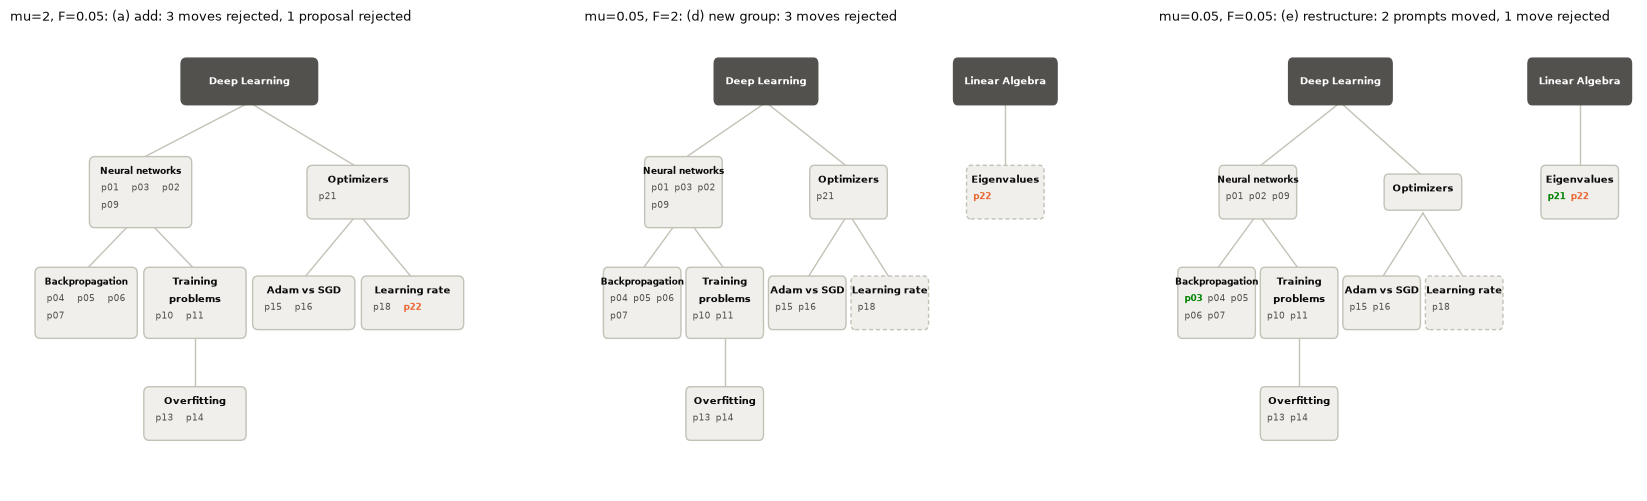

In [12]:
distinct = sorted(set(grid_actions.values()))
fig, axes = plt.subplots(1, len(distinct), figsize=(7 * len(distinct), 6))
axes = np.atleast_1d(axes)
for ax, a in zip(axes, distinct):
    mu, F_ = next(k for k, v in grid_actions.items() if v == a)
    after, dec = solve(best.before, best.prompt, best.judge, best.step, P.replace(mu=mu, F=F_))
    viz.draw_forest(after, ax, viz.Overlay(new_prompt=best.prompt.id, moved=set(dec.diff["moved_prompts"]) | set(dec.diff["moved_topics"])),
                    P=P, title=f"mu={mu:.2g}, F={F_:.2g}: {viz.action_summary(dec)}")
fig.savefig(FIG / "03_whatif_flip_forests.png", dpi=130, bbox_inches="tight")
plt.show()

## Findings

- **Non-trivial:** given the same judge output, the IP places the new prompt differently from
  `judge_argmax` in 32 % of the steps with the perfect oracle, and in 8 % with noise 0.2.
- **Agreement:** with a perfect oracle, taking its top option rebuilds the ideal forest exactly
  (topic-pair F1 1.0). With noise 0.2 it reaches 0.93. The IP ends at 0.79 with both, because new
  topics, splits and moves cost something; it restructures once (step 17). `chronological` reaches
  0.18. These are oracle runs, where the judge is right by construction; the LLM runs, where it is
  not, are still open.
- **What-if, stability weights:** with `mu = 2` the IP never restructures and ends at F1 0.70. With
  `mu <= 0.13` and `F <= 0.32` it restructures 3 times and reaches 0.89. `mu = 0.05, F = 0.8` rebuilds
  the ideal forest (1.0). Weighted moved prompts rise from 0 to at most 7.0.
- **What-if, one step** (step 17 of the noisy run, an eigenvector question): the IP adds it to an
  existing topic at `mu = 2`, opens a new group (d) at `mu = 0.8` or `F = 2`, and restructures (e)
  below both (grid above). In the "add" case it puts the
  eigenvector question into Learning rate. Every existing topic fits it equally badly, and filling a
  topic below `L` saves `beta`: a side effect of the balance term the report should discuss.
- **Intended vs actual:** the intended (e) at step 13 (insert Training problems) and step 20 (split
  the optimizer topic) do not happen with the default weights; the restructure comes at step 17
  instead. *The group's interpretation goes here.*